# 10.18 — Intel Lab temperature prediction and GP–GRG replay

This is Johnson Ji 10.18 test, using intel lab temp data to do the python simulation of closed loop GP+GRG navigation.

Objective: evaluate the existing 3D ARD RBF GP on recorded temperatures, then verify closed-loop sampling under the revised GRG policies.

Source: [Intel Lab repository](https://github.com/linsea423/Intel_Lab_Data), [original dataset](https://db.csail.mit.edu/labdata/labdata.html).
Train on 2004-02-29 to 2004-03-02; test on 2004-03-03. Select exactly 2,000 real records with day quotas 667/667/666, near-equal sensor quotas and equally spaced time targets. Fixed seed 18 assigns remainders. Preserve original coordinates, record IDs and times. Use a fixed 0–50°C plausibility screen; no imputation or interpolation.

Reuse the existing 3D ARD RBF GP and 300-step fit. Fit normalization and all parameters on the selected history only. All temperature-performance tables and figures below come from the Intel experiment. Dense maps are GP estimates; the map and navigation remain simulated. Section 4 reports program correctness checks separately.

## Data and fitted model

Historical interval: [2004-02-29 00:00, 2004-03-03 00:00). Test interval: [2004-03-03 00:00, 2004-03-04 00:00). Time is continuous hours from 2004-02-29 00:00; original timezone is unspecified. The cleaned history pool has 280,944 records. The test day has 90,690 valid records. The fixed screen excludes 151 history and 205 test temperature records; 40 additional four-day records lack sensor/temperature values. This screen does not certify all retained readings.


In [1]:
from pathlib import Path
import csv
import json
from IPython.display import Image, Markdown, display
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'testing_code/baseline/config.json').is_file())
result = root / '10.18_result'
intel = result / 'baseline/intel_lab'
forecast = json.loads((intel / 'forecast/summary.json').read_text())
mission = json.loads((intel / 'replay/summary.json').read_text())
depth = json.loads((result / 'grg_depth_benchmark/intel_lab/depth_summary.json').read_text())
workspace = root.parents[1]
split = json.loads((workspace / 'Data/Intel_lab_data/processed/three_day_2000/split.json').read_text())
def show(columns, rows):
    lines = [' | '.join(columns), ' | '.join(['---'] * len(columns))]
    lines += [' | '.join(f'{v:.6g}' if isinstance(v, float) else str(v) for v in row) for row in rows]
    display(Markdown('\n'.join(lines)))
show(['Condition', 'Value'], [[key, split[key]] for key in
     ['train_interval', 'test_interval', 'train_count', 'train_rows_per_day', 'train_sensor_count', 'test_count']])
selected_path = workspace / 'Data/Intel_lab_data/processed/three_day_2000/train_2000.csv'
with selected_path.open() as stream:
    selected = list(csv.DictReader(stream))
assert len(selected) == 2000
assert len({r['record_id'] for r in selected}) == 2000
show(['Selected real record', 'Sensor', 'Timestamp', 'x (m)', 'y (m)', 'Temperature (C)'],
     [[r[k] for k in ['record_id','sensor_id','timestamp','x_m','y_m','temperature_c']] for r in selected[:5]])
hp = json.loads((intel / 'forecast/hyperparameters.json').read_text())
show(['Fitted parameter', 'Value'], [[k, hp[k]] for k in
     ['kernel','lengthscales_m_m_h','output_variance_c2','noise_variance_c2','mean_c','selected_iteration']])

Condition | Value
--- | ---
train_interval | [2004-02-29 00:00, 2004-03-03 00:00)
test_interval | [2004-03-03 00:00, 2004-03-04 00:00)
train_count | 2000
train_rows_per_day | [667, 667, 666]
train_sensor_count | 53
test_count | 90690

Selected real record | Sensor | Timestamp | x (m) | y (m) | Temperature (C)
--- | --- | --- | --- | --- | ---
2149268 | 50 | 2004-02-29 00:53:51.441372 | 38.5 | 1.0 | 16.3036
1796924 | 43 | 2004-02-29 00:54:50.544743 | 35.5 | 24.0 | 17.9892
340015 | 10 | 2004-02-29 00:54:50.890202 | 19.5 | 5.0 | 18.9202
1379 | 1 | 2004-02-29 00:55:18.378039 | 21.5 | 23.0 | 18.9006
1297399 | 32 | 2004-02-29 00:55:18.513495 | 17.5 | 31.0 | 18.0774

Fitted parameter | Value
--- | ---
kernel | ScaleKernel(RBF_ARD_xy * RBF_t) == 3D ARD RBF
lengthscales_m_m_h | [19.65214598283966, 25.751149934787165, 2.7902345302784974]
output_variance_c2 | 21.858
noise_variance_c2 | 0.944244
mean_c | 19.3554
selected_iteration | 300

## 1. Fourth-day temperature prediction

Goal: forecast the complete test day from the fixed origin at 72 h. Predict at the actual sensor positions and recorded timestamps of all 90,690 valid measurements. Add no fourth-day data to the GP. Compare predictive mean with measured temperature. Report observation intervals, including learned likelihood noise. Source: [forecast.py](testing_code/intel_lab/forecast.py).


Metric | Value
--- | ---
rmse_c | 4.93747
mae_c | 3.57528
coverage_95 | 0.910453
nlpd | 2.93166
interval_width_95_c | 17.5426
z_mean | 0.607864
z_std | 0.839913

Timing | Seconds
--- | ---
training_s | 85.0279
prediction_s | 34.5031

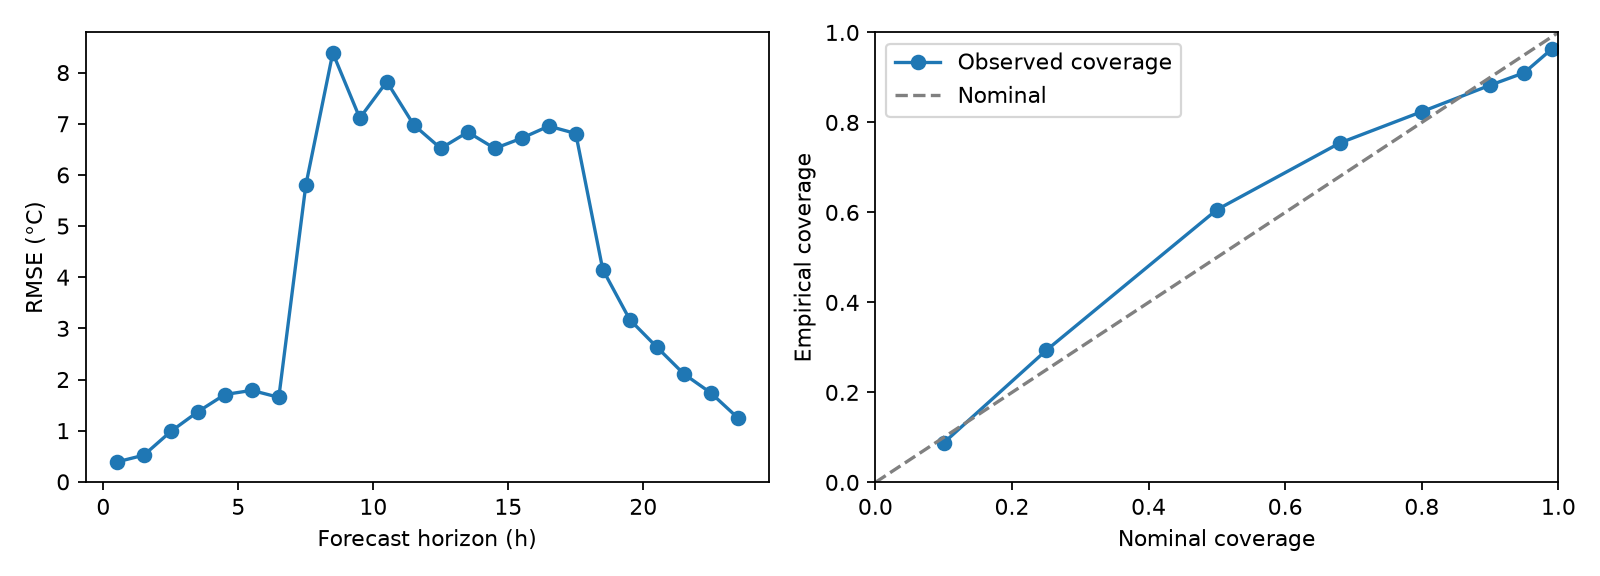

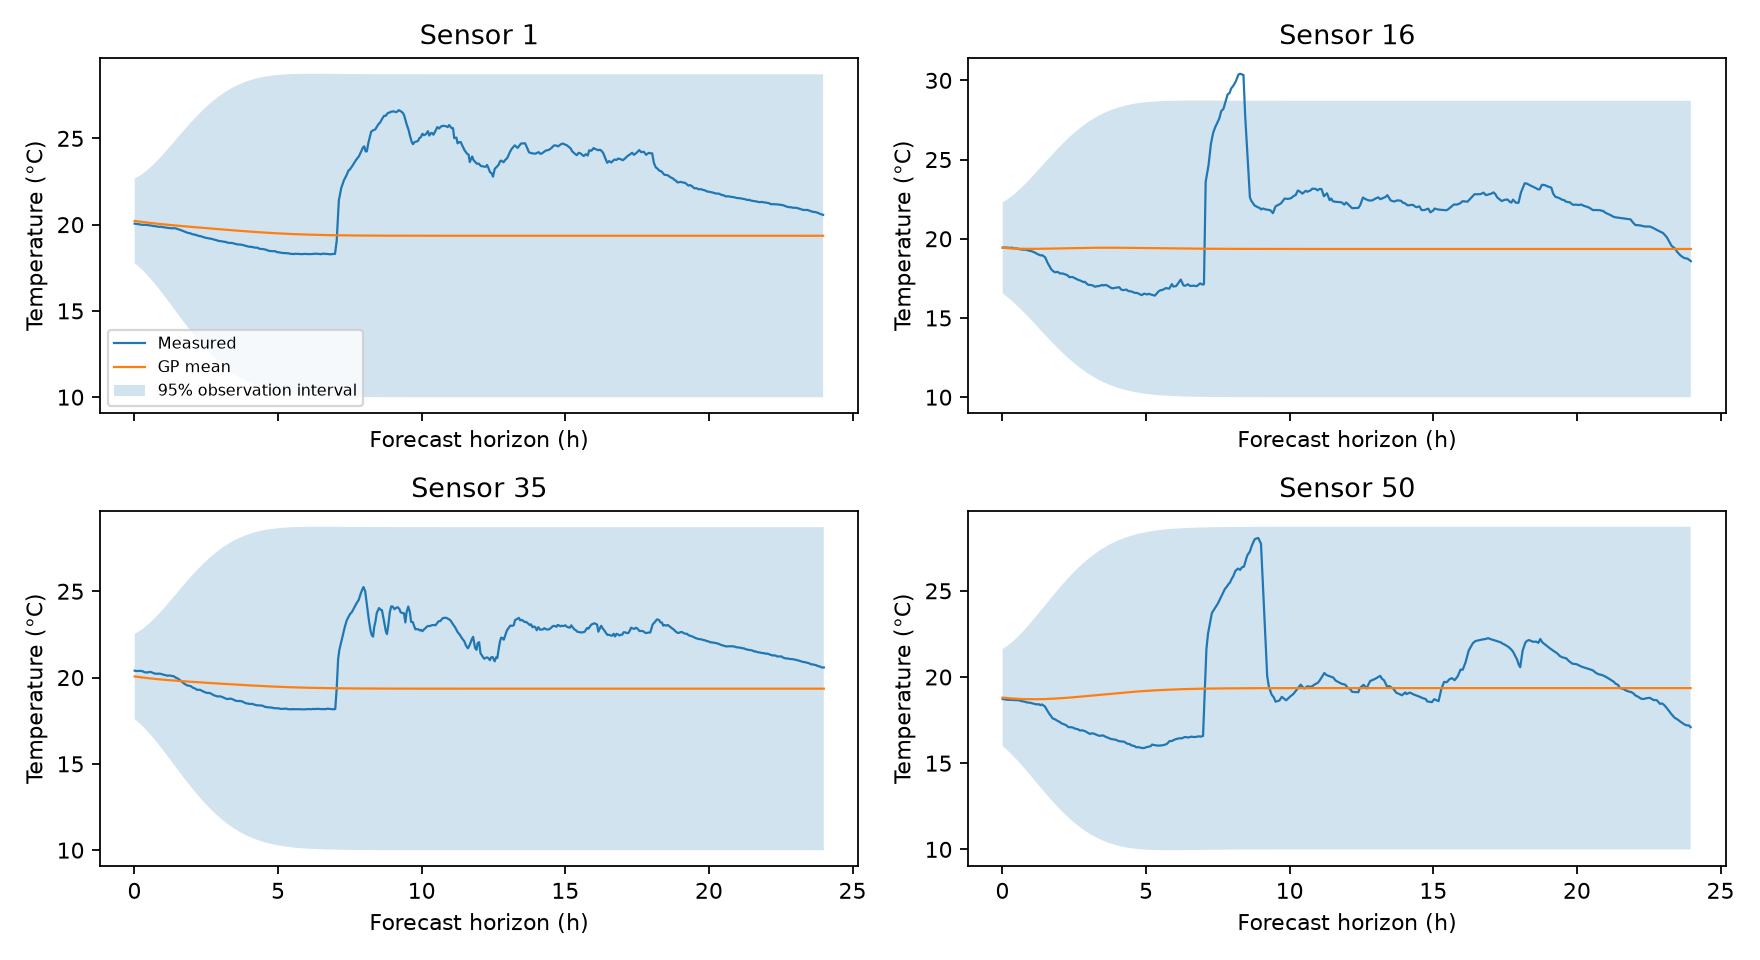

In [2]:
show(['Metric', 'Value'], list(forecast['metrics'].items()))
show(['Timing', 'Seconds'], [[k, forecast[k]] for k in ['training_s', 'prediction_s']])
for name in ['forecast_metrics.png', 'sensor_forecasts.png']:
    display(Image(filename=str(intel / 'forecast/figures' / name)))

Conclusion: RMSE is 4.937°C and MAE is 3.575°C. Coverage is 91.05% with mean interval width 17.543°C. The current RBF has limited full-day forecast accuracy. The mean approaches its learned constant away from history, while uncertainty widens. No kernel comparison or performance tuning was performed.


## 2. Intel GP–GRG baseline replay

Goal: test recorded sampling and online reconstruction. Keep the 30×30 m simulated map. Home is sensor 16 at (1.5,2) m; use 29 footprint-reachable sensor candidates. Allow revisits and Home measurements. Wait for the next available record, charge waiting and 5 s dwell, and condition on its actual time. Only acquisition timestamps enter planning; future temperature values do not.

The mission covers the first 900 s of the fourth day. Within each sensor, even-indexed time-ordered records form the acquisition pool; odd-indexed records form a disjoint evaluation pool. GRG uses the same posterior sampling-point joint MI, evaluated at actual estimated acquisition times.

RMSE uses 28 fixed held-out records in the final five-minute reference window, with their actual recorded temperatures and timestamps. These timestamps differ. Final reconstruction can use online measurements later than some reference records. The 0.75 m dense maps at 72.25 h show GP predictions and latent uncertainty; dense real-field error is unavailable. This short retrospective reconstruction and the full-day forecast have different targets. Source: [replay.py](testing_code/intel_lab/replay.py).


Mission | Value
--- | ---
measurements | 7
planning_calls | 8
elapsed_s | 870.259
returned_home | True
measurement_wait_time_s | 368.148
dwell_time_s | 35
information_gain_nats | 2.15273

Stage | RMSE (C) | Mean latent variance (C2)
--- | --- | ---
History only | 0.489578 | 1.11523
After online samples | 0.546907 | 0.430121

{'passed': True,
 'checks': {'returned_home': True,
  'within_budget': True,
  'clock_accounting': True,
  'unique_record_ids': True,
  'no_evaluation_leakage': True,
  'gp_observation_count': True,
  'only_successful_gp_updates': True,
  'parameters_frozen': True,
  'all_plans_feasible': True,
  'reward_chain_rule': True,
  'chronological_measurements': True,
  'path_collision_free': True}}

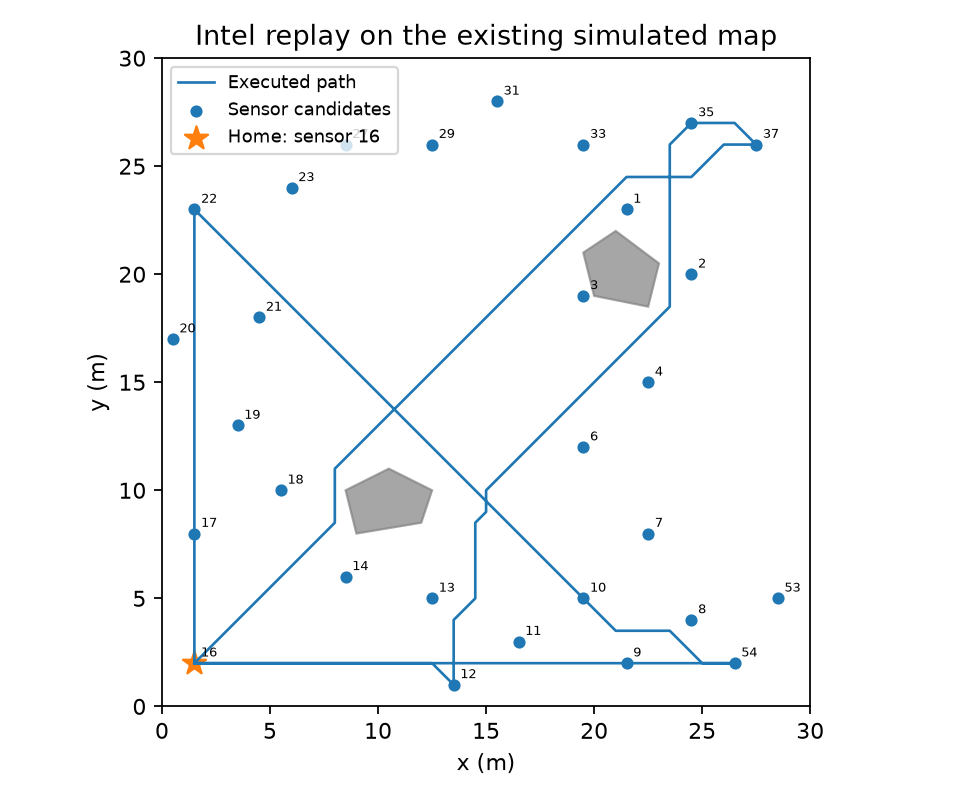

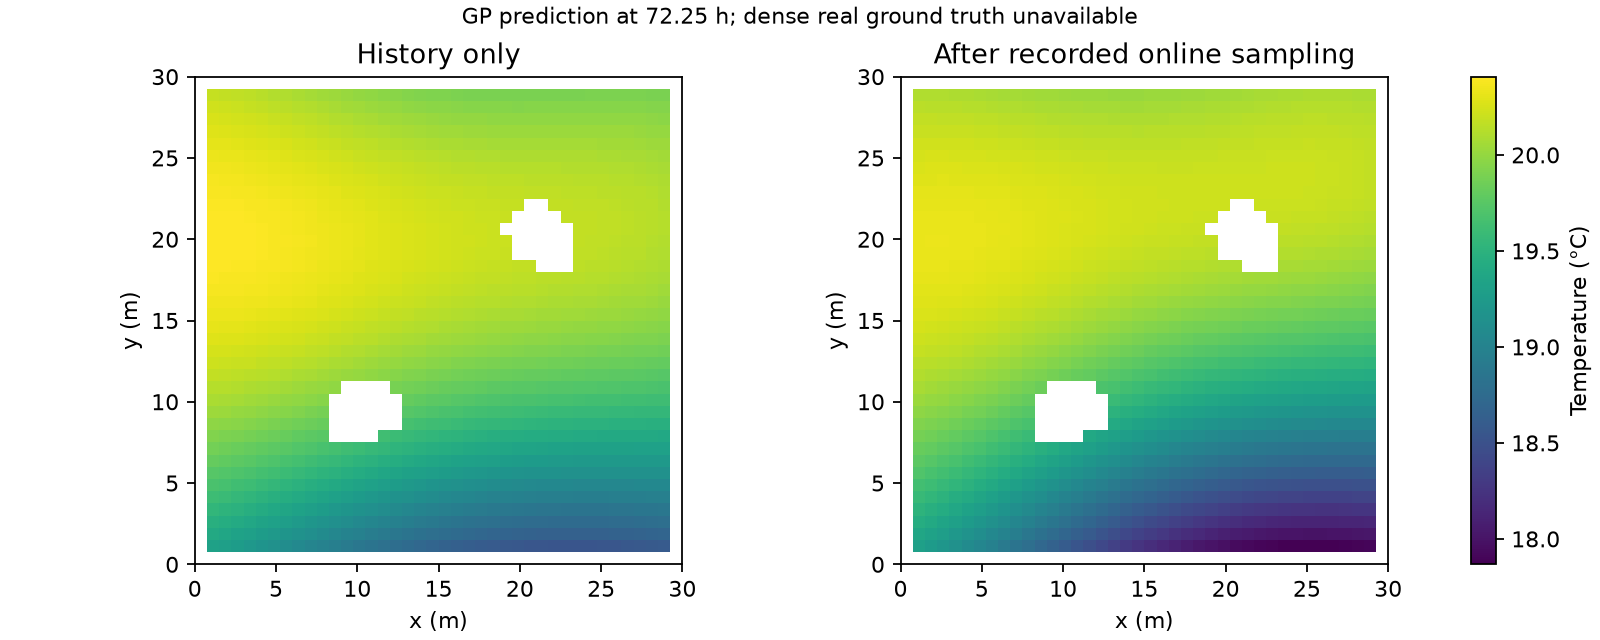

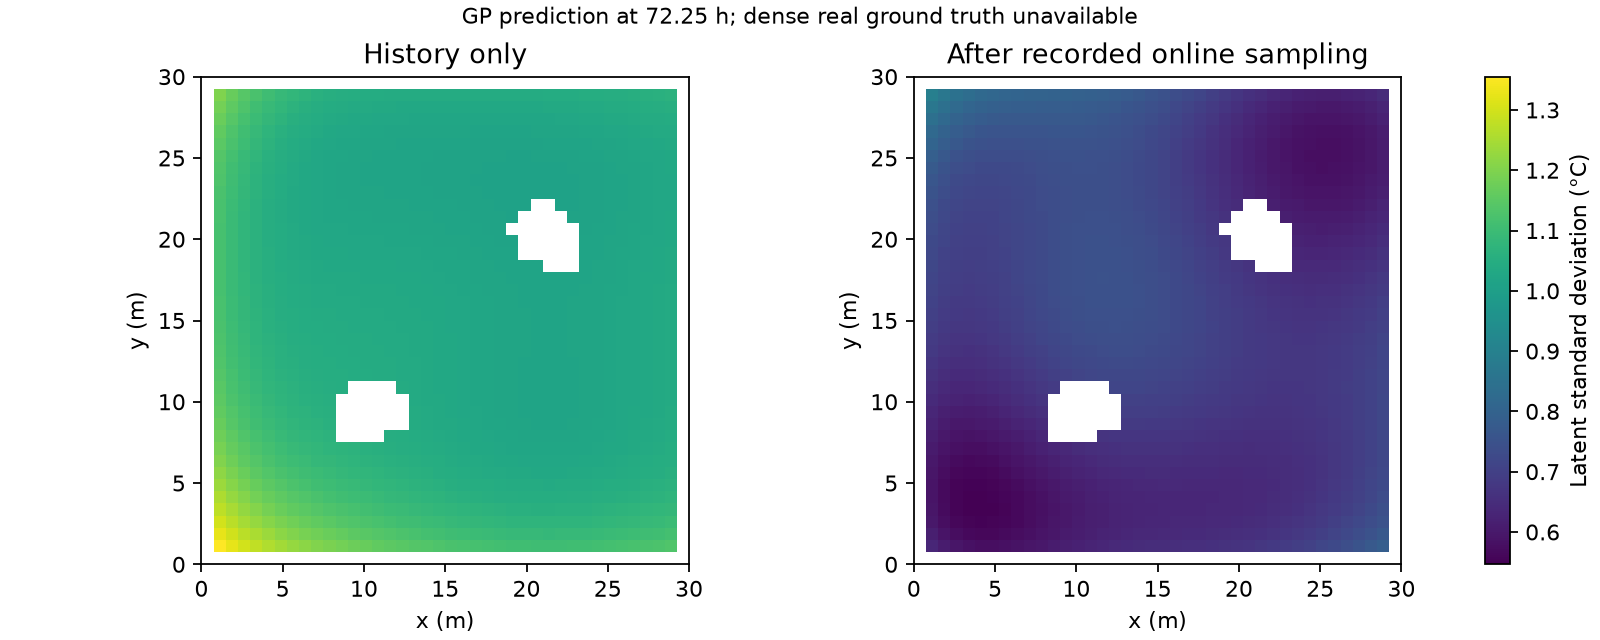

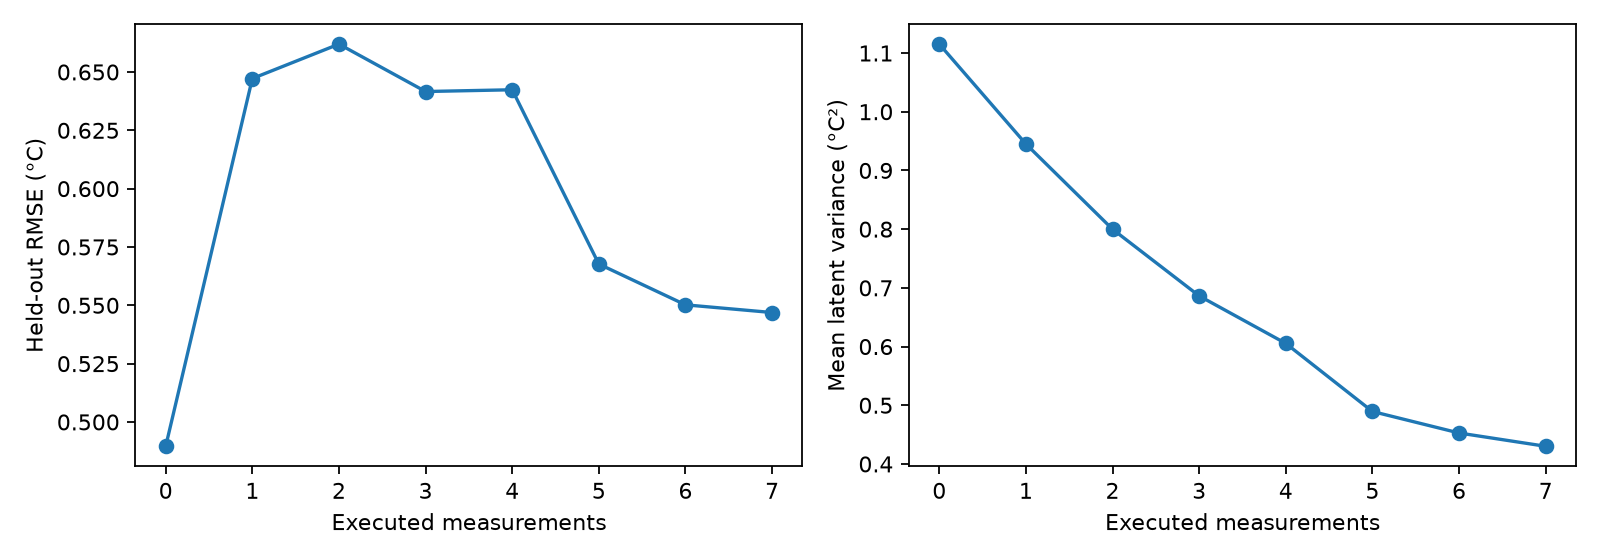

In [3]:
show(['Mission', 'Value'], [[k, mission[k]] for k in ['measurements', 'planning_calls', 'elapsed_s', 'returned_home', 'measurement_wait_time_s', 'dwell_time_s', 'information_gain_nats']])
show(['Stage', 'RMSE (C)', 'Mean latent variance (C2)'],
     [[name, mission[key]['rmse_c'], mission[key]['mean_variance_c2']] for name,key in
      [('History only','initial_metrics'),('After online samples','final_metrics')]])
display(json.loads((intel / 'replay/verification.json').read_text()))
for name in ['navigation.png', 'temperature_maps.png', 'uncertainty_maps.png', 'reconstruction_metrics.png']:
    display(Image(filename=str(intel / 'replay/figures' / name)))

Conclusion: the robot collected 7 distinct real records and returned at 870.26 s. Held-out RMSE increased from 0.48958 to 0.54691°C. Mean latent variance decreased from 1.11523 to 0.43012°C². This run reduces modeled uncertainty but does not improve temperature accuracy on the reference records. All recorded-data mission checks pass.


## 3. Recursive-depth benchmark on Intel replay

Use identical history, checkpoint, sensor candidates, availability and held-out references. Change depth only. Check a deterministic depth-2 repeat. Planning and worker watchdogs are 90 s and 900 s wall time; neither is charged to the idealized mission clock. Depth 5 is excluded. One fixed dataset does not provide independent stochastic trials.


Depth | Status | Samples | Final RMSE (C) | MI (nats) | GRG time (s)
--- | --- | --- | --- | --- | ---
1 | SUCCESS | 6 | 0.569799 | 1.89694 | 0.022234
2 | SUCCESS | 7 | 0.546907 | 2.15273 | 2.9357
3 | SUCCESS | 12 | 0.490406 | 2.90277 | 238.624

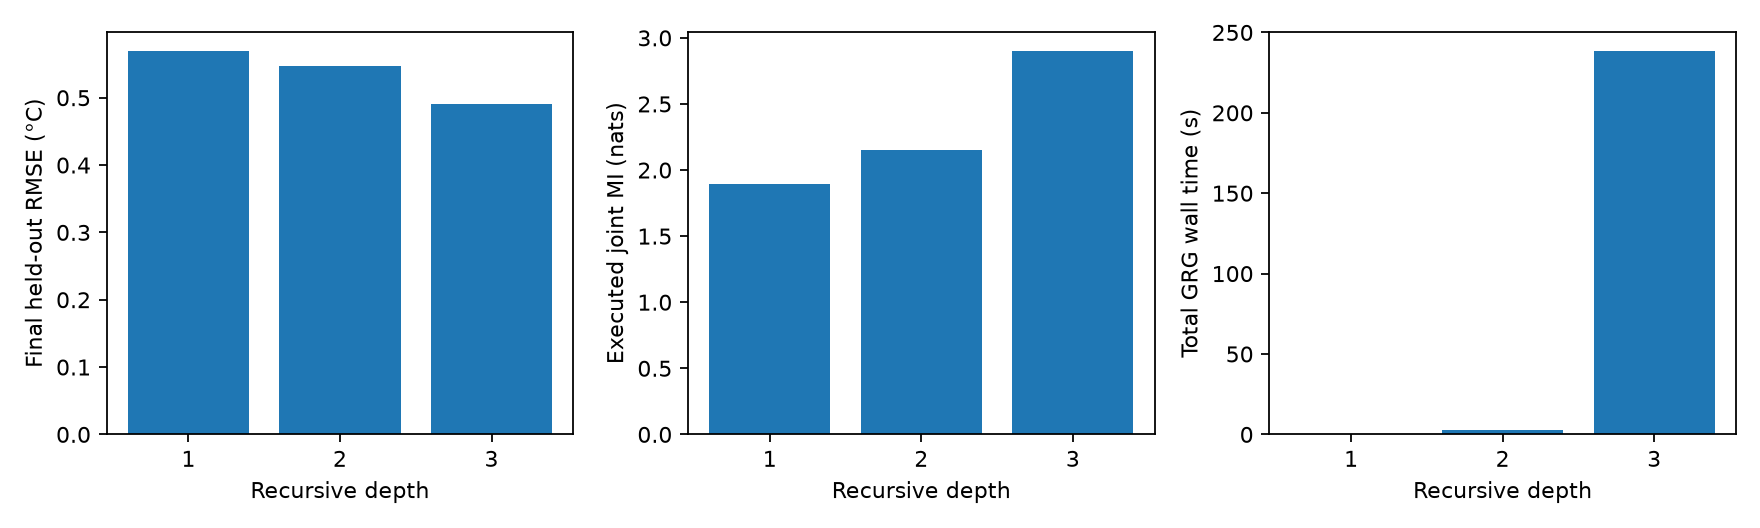

{'passed': True,
 'checks': {'online_measurements.csv': True,
  'robot_trajectory.csv': True,
  'metrics.csv': True,
  'routes_and_times': True}}

In [4]:
show(['Depth','Status','Samples','Final RMSE (C)','MI (nats)','GRG time (s)'],
     [[r['depth'],r['status'],r.get('measurements'),r.get('final_rmse_c'),r.get('mi_nats'),r.get('grg_runtime_s')] for r in depth])
display(Image(filename=str(result / 'grg_depth_benchmark/intel_lab/figures/depth_comparison.png')))
display(json.loads((result / 'grg_depth_benchmark/intel_lab/repeat_verification.json').read_text()))

Conclusion: all three depths return within budget. Depth 3 collects more observations and MI, with lower posterior variance and much higher planning time. Its final RMSE is slightly above the initial 0.48958°C; none of these runs improves on the history-only RMSE. The depth-2 repeat reproduces observations, trajectory, metrics, routes and event times. Depth 5 is excluded.


## 4. Correctness and data-provenance checks

These are current program-verification results. Recursive, navigation and failure tests use bounded controlled fixtures, including a historical synthetic-trained checkpoint. They do not measure Intel temperature-field performance. Intel-specific checks use the current 2,000-record GP and real-record acquisition rules.

Allow A–B–A and A–A, with separate event times and dwells. Merge shared recursive junctions once. Preserve posterior joint MI, deadlines, return reserves and static reachability. Temporary navigation failure excludes exactly the next top-level cycle. Execute a real alternative action to reach a later cycle; otherwise terminate and return safely. Do not spin empty planning cycles.

Retain numerical and navigation tests. Replace spatial-uniqueness assertions with explicit-event checks. Replay additionally verifies record-time matching, acquisition waits, no record reuse and executed-only GP updates. Source: [updated tests](testing_code/grg_correctness/test_recursive.py), [failure tests](testing_code/baseline/test_failures.py), [replay tests](testing_code/intel_lab/test_replay.py).


In [5]:
correctness = result / 'grg_correcness/current'
for name in ['new_tests.json', 'numerical_summary.json', 'regressions.json', 'intel_replay_tests.json']:
    display(Markdown('**' + name + '**'))
    display(json.loads((correctness / name).read_text()))
display(json.loads((correctness / 'obstacle_map_reproduction.json').read_text()))

**new_tests.json**

{'passed': True,
 'count': 8,
 'failures': 0,
 'errors': 0,
 'tests': [{'test': 'test_recursive.RecursiveChecks.test_01_bounded_exhaustive_repeated_routes',
   'status': 'PASS'},
  {'test': 'test_recursive.RecursiveChecks.test_02_recursive_deadlines_prefixes_and_junctions',
   'status': 'PASS'},
  {'test': 'test_recursive.RecursiveChecks.test_03_consecutive_nonconsecutive_and_previous_visits',
   'status': 'PASS'},
  {'test': 'test_recursive.RecursiveChecks.test_04_cache_depth_time_prefix_order_and_posterior',
   'status': 'PASS'},
  {'test': 'test_recursive.RecursiveChecks.test_05_joint_mi_history_online_and_temporal_covariance',
   'status': 'PASS'},
  {'test': 'test_recursive.RecursiveChecks.test_06_zero_distance_dwell_exact_budget_and_return',
   'status': 'PASS'},
  {'test': 'test_recursive.RecursiveChecks.test_07_candidates_and_one_top_level_failure_cycle',
   'status': 'PASS'},
  {'test': 'test_recursive.RecursiveChecks.test_08_obstacle_paths_and_previous_depth3_reproduction',
 

**numerical_summary.json**

{'maximum_mi_difference_nats': 1.4235723710953607e-11,
 'recursive_subproblems_checked': 269,
 'cache_states_checked': 18,
 'bounded_exhaustive_cases': 12}

**regressions.json**

[{'suite': 'baseline',
  'command': ['/Users/jihaoran/Documents/4RP3/Code/10.16_GP3D_baseline_test/10.16_testing_code/.venv/bin/python',
   '-m',
   'unittest',
   'discover',
   '-s',
   'testing_code/baseline',
   '-p',
   'test_*.py',
   '-v'],
  'passed': True,
  'returncode': 0},
 {'suite': 'benchmark',
  'command': ['/Users/jihaoran/Documents/4RP3/Code/10.16_GP3D_baseline_test/10.16_testing_code/.venv/bin/python',
   'testing_code/grg_depth_benchmark/test_benchmark.py'],
  'passed': True,
  'returncode': 0}]

**intel_replay_tests.json**

{'passed': True,
 'count': 5,
 'failures': 0,
 'errors': 0,
 'evidence': {'recorded_time_mi_difference_nats': 4.551914400963142e-15}}

{'original_route': [0, 3, 1, 2, 3, 0],
 'arrivals_s': [81.38651821211016,
  148.7534528542421,
  211.9956708852428,
  273.8513707041333],
 'finish_s': 360.23788891624343,
 'dwell_s': 20.0,
 'event_count': 4,
 'valid_revisit_route': True,
 'current_route': [0, 3, 0, 2, 1, 3, 0, 1, 0],
 'interpretation': 'Two explicit node-3 events with distinct times and dwells. The shared recursive junction is passed once in the prefix, not concatenated twice.'}

The earlier route `[0,3,1,2,3,0]` is valid under the new event semantics: four measurements, two distinct node-3 timestamps, four dwells, joint covariance of all events, feasible obstacle-aware return. Recursive prefix tracing checks that a shared junction is not duplicated. These bounded tests do not prove global optimality or correctness for arbitrary depth. Partial-motion recovery retains safe return from the actual pose; arbitrary-pose replanning and ROS/Nav2 remain future work.
